In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
import matplotlib as mpl
from mpl_toolkits.mplot3d import axes3d

from matplotlib import cm
from matplotlib.colors import Normalize
import matplotlib.colorbar as clb
from matplotlib import gridspec
from matplotlib.patches import Rectangle

import pickle

ROOT = Path().resolve().parents[1]
sys.path.append(str(ROOT / "src"))

from forward import magcal
from forward import magcal_numba
from forward.thread_func import thread_func

In [2]:
def calc_rmse(model1, model2):
    return np.sqrt(np.linalg.norm(model1 - model2, ord=2)**2 / len(model1))

### Model domain

In [3]:
### Construction of subsurface grid: xgrd, ygrd, zgrd ###
# incx, incy, incz : grid spacing in x, y, z directions
incx = 0.1
incy = 0.1
incz = 0.1

x = np.arange(-2.4 + 0.5*incx, 2.4, incx)
y = np.arange(-2.4 + 0.5*incy, 2.4, incy)
z = np.arange(-2.4 + 0.5*incz, 0.0, incz)
            
nx = len(x)
ny = len(y)
nz = len(z)
print("nx = {}, ny = {}, nz = {}".format(nx, ny, nz))

### Construction of subsurface grid: xgrd, ygrd, zgrd ###
[yy2, zz2, xx2] = np.meshgrid(y, z, x)
            
xgrd = xx2.reshape(-1)
ygrd = yy2.reshape(-1)
zgrd = zz2.reshape(-1)

# For visualization
xfig, yfig, zfig = [], [], []

for i in range(len(xgrd)):
    j = i // (nx*ny)
    
    # Store coordinates of 8 vertices of each grid cell
    xfig.append([xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx, xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx, 
                 xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx, xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx])
    yfig.append([ygrd[i] - 0.5*incy, ygrd[i] - 0.5*incy, ygrd[i] + 0.5*incy, ygrd[i] + 0.5*incy, 
                 ygrd[i] - 0.5*incy, ygrd[i] - 0.5*incy, ygrd[i] + 0.5*incy, ygrd[i] + 0.5*incy])
    zfig.append([zgrd[i] - 0.5*incz, zgrd[i] - 0.5*incz, zgrd[i] - 0.5*incz, zgrd[i] - 0.5*incz, 
                 zgrd[i] + 0.5*incz, zgrd[i] + 0.5*incz, zgrd[i] + 0.5*incz, zgrd[i] + 0.5*incz])

# Convert to numpy arrays
xfig = np.array(xfig)
yfig = np.array(yfig)
zfig = np.array(zfig)

# Block size
dim = [[incx / 2., incx / 2.], [incy / 2., incy / 2.], [incz / 2., incz / 2.]]

# Near Tokyo
# Declination (degrees)
dec = -7.
# Inclination (degrees)
inc = 50.

nx = 48, ny = 48, nz = 24


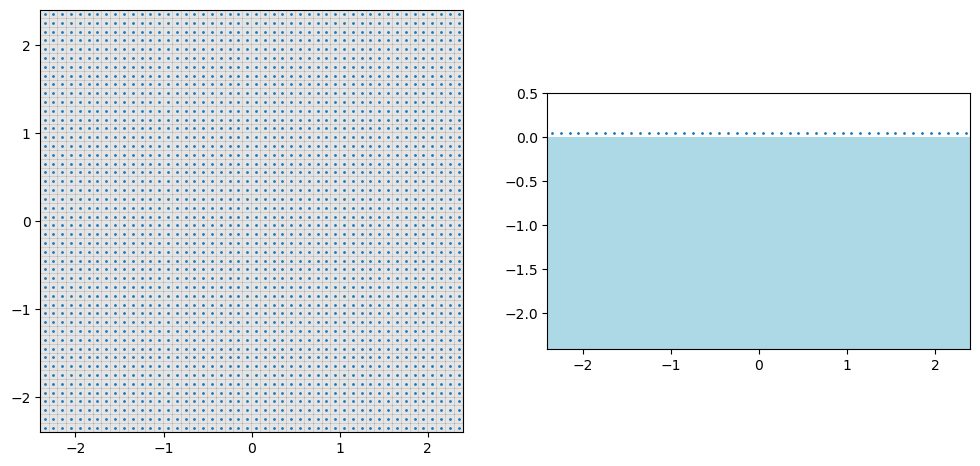

In [4]:
### Generate synthetic data ###
# Coordinate system: x positive east, y positive north, z positive upward

### Observation points: yobs, zobs ###
[xobs1, yobs1] = np.meshgrid(
    np.arange(-2.4 + 0.5*incx, 2.4, incx),
    np.arange(-2.4 + 0.5*incy, 2.4, incy)
)
xobs1 = xobs1.reshape(-1)
yobs1 = yobs1.reshape(-1)
zobs1 = 0.05 *np.ones(len(xobs1))

# Plotting
from matplotlib import cm
from matplotlib.colors import Normalize
import matplotlib.colorbar as clb
from matplotlib import gridspec
from matplotlib.patches import Rectangle

fig = plt.figure(figsize = (12, 6))

ax = fig.add_subplot(121)
ax.pcolor(xx2[0,:,:], yy2[0,:,:], np.zeros(xx2[0,:,:].shape), cmap = "gray", alpha = 0.1)
ax.scatter(xobs1, yobs1, s = 1)
ax.set_aspect("equal")

ax = fig.add_subplot(122)

ax.scatter(xobs1[(0<yobs1)&(yobs1<incy)], zobs1[(0<yobs1)&(yobs1<incy)], s = 1)

# Cross-section visualization
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (y_min <= 0.5*incy) & (0.5*incy <= y_max):
        
        # Block dimensions
        width  = x_max - x_min
        height = z_max - z_min

        # Draw rectangle
        rect = Rectangle((x_min, z_min), width, height,
                         facecolor="lightblue", edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.5)
ax.set_aspect("equal")

In [5]:
from numba import njit, prange

@njit(parallel=True, fastmath=True)
def kernel_matrix2(
    exf,
    mgz,
    xobs,
    yobs,
    zobs,
    xgrd,
    ygrd,
    zgrd,
    dim,
    L
):

    nobs  = xobs.shape[0]
    ncell = xgrd.shape[0]

    xmin = np.min(xgrd)
    xmax = np.max(xgrd)

    ymin = np.min(ygrd)
    ymax = np.max(ygrd)

    K = np.zeros((nobs, ncell))

    for s in prange(ncell):

        dx1 = dim[0,0]
        dx2 = dim[0,1]

        dy1 = dim[1,0]
        dy2 = dim[1,1]

        dz1 = dim[2,0]
        dz2 = dim[2,1]

        if abs(xgrd[s] - xmin) < 1e-10:
            dx1 += L
        elif abs(xgrd[s] - xmax) < 1e-10:
            dx2 += L

        if abs(ygrd[s] - ymin) < 1e-10:
            dy1 += L
        elif abs(ygrd[s] - ymax) < 1e-10:
            dy2 += L

        dim_new = np.empty((3,2))

        dim_new[0,0] = dx1
        dim_new[0,1] = dx2

        dim_new[1,0] = dy1
        dim_new[1,1] = dy2

        dim_new[2,0] = dz1
        dim_new[2,1] = dz2

        h = magcal_numba.prism(
            mgz,
            xobs,
            yobs,
            zobs,
            xgrd[s],
            ygrd[s],
            zgrd[s],
            dim_new
        )

        K[:,s] = magcal_numba.total_force(exf, h)

        if s%1000 == 0: 
            print(s) 

    return K

In [6]:
%%time
# num of threads
from numba import set_num_threads, get_num_threads
set_num_threads(12)
print(get_num_threads())

# Unit vector creation
mgz = magcal.di2xyz(dec = dec, inc = inc)
exf = mgz.copy()

# Kernel matrix
K1 = kernel_matrix2(
     exf,
     mgz,
     xobs1.astype(np.float64),
     yobs1.astype(np.float64),
     zobs1.astype(np.float64),
     xgrd.astype(np.float64),
     ygrd.astype(np.float64),
     zgrd.astype(np.float64),
     np.array(dim, dtype=np.float64),
     1000.0
)

12
0
37000
14000
51000
28000
5000
42000
19000
33000
10000
24000
47000
1000
38000
15000
52000
29000
6000
43000
20000
34000
11000
25000
48000
2000
39000
53000
16000
30000
7000
44000
35000
21000
12000
26000
3000
49000
40000
54000
17000
45000
31000
8000
36000
13000
22000
27000
41000
4000
55000
50000
46000
18000
9000
32000
23000
CPU times: total: 2min 42s
Wall time: 42.2 s


### Input models and data

In [7]:
### Magnetization structure  ###

# ------------------------------------------------------------ #

# Time 1
beta1 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 南: block
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (-1.4 < ygrd[k]) & (ygrd[k] < -0.6) & (-1.4 < zgrd[k]) & (zgrd[k] < -0.6):
                beta1[k] = 4

# Time 2
beta2 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 南: block
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (-1.4 < ygrd[k]) & (ygrd[k] < -0.6) & (-1.4 < zgrd[k]) & (zgrd[k] < -0.6):
                beta2[k] = 3.5


# Time 3
beta3 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 北: dyke
            if (-0.1 < xgrd[k]) & (xgrd[k] < 0.1) & (0.0 < ygrd[k]) & (ygrd[k] < 1.6) & (-1.0 < zgrd[k]) & (zgrd[k] < -0.4):
                beta3[k] = -4.0
            
            # 南: block
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (-1.4 < ygrd[k]) & (ygrd[k] < -0.6) & (-1.4 < zgrd[k]) & (zgrd[k] < -0.6):
                beta3[k] = 2.5
                
# Time 4
beta4 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 北: dyke
            if (-0.1 < xgrd[k]) & (xgrd[k] < 0.1) & (0.0 < ygrd[k]) & (ygrd[k] < 1.6) & (-1.0 < zgrd[k]) & (zgrd[k] < -0.4):
                beta4[k] = -4.0        

             # 南: block
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (-1.4 < ygrd[k]) & (ygrd[k] < -0.6) & (-1.4 < zgrd[k]) & (zgrd[k] < -0.6):
                beta4[k] = 1
                
bb1 = beta1.reshape(nz, ny, nx)
bb2 = beta2.reshape(nz, ny, nx)
bb3 = beta3.reshape(nz, ny, nx)
bb4 = beta4.reshape(nz, ny, nx)

# ------------------------------------------------------------ #

# Magnetic anomaly calculation
f1_row = K1.dot(beta1)
f2_row = K1.dot(beta2)
f3_row = K1.dot(beta3)
f4_row = K1.dot(beta4)

# Centering
f1_row = f1_row - f1_row.mean()
f2_row = f2_row - f2_row.mean()
f3_row = f3_row - f3_row.mean()
f4_row = f4_row - f4_row.mean()

# Add Gaussian noise
np.random.seed(42)
noise1 = np.random.normal(loc=0, scale=5.0, size=len(f1_row))  # 5 nT
noise2 = np.random.normal(loc=0, scale=5.0, size=len(f2_row))  # 5 nT
noise3 = np.random.normal(loc=0, scale=5.0, size=len(f3_row))  # 5 nT
noise4 = np.random.normal(loc=0, scale=5.0, size=len(f4_row))  # 5 nT

fobs1 = f1_row + noise1
fobs2 = f2_row + noise2
fobs3 = f3_row + noise3
fobs4 = f4_row + noise4


<timed exec>:436: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
<timed exec>:466: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
<timed exec>:496: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
<timed exec>:526: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.


CPU times: total: 40.9 s
Wall time: 41.8 s


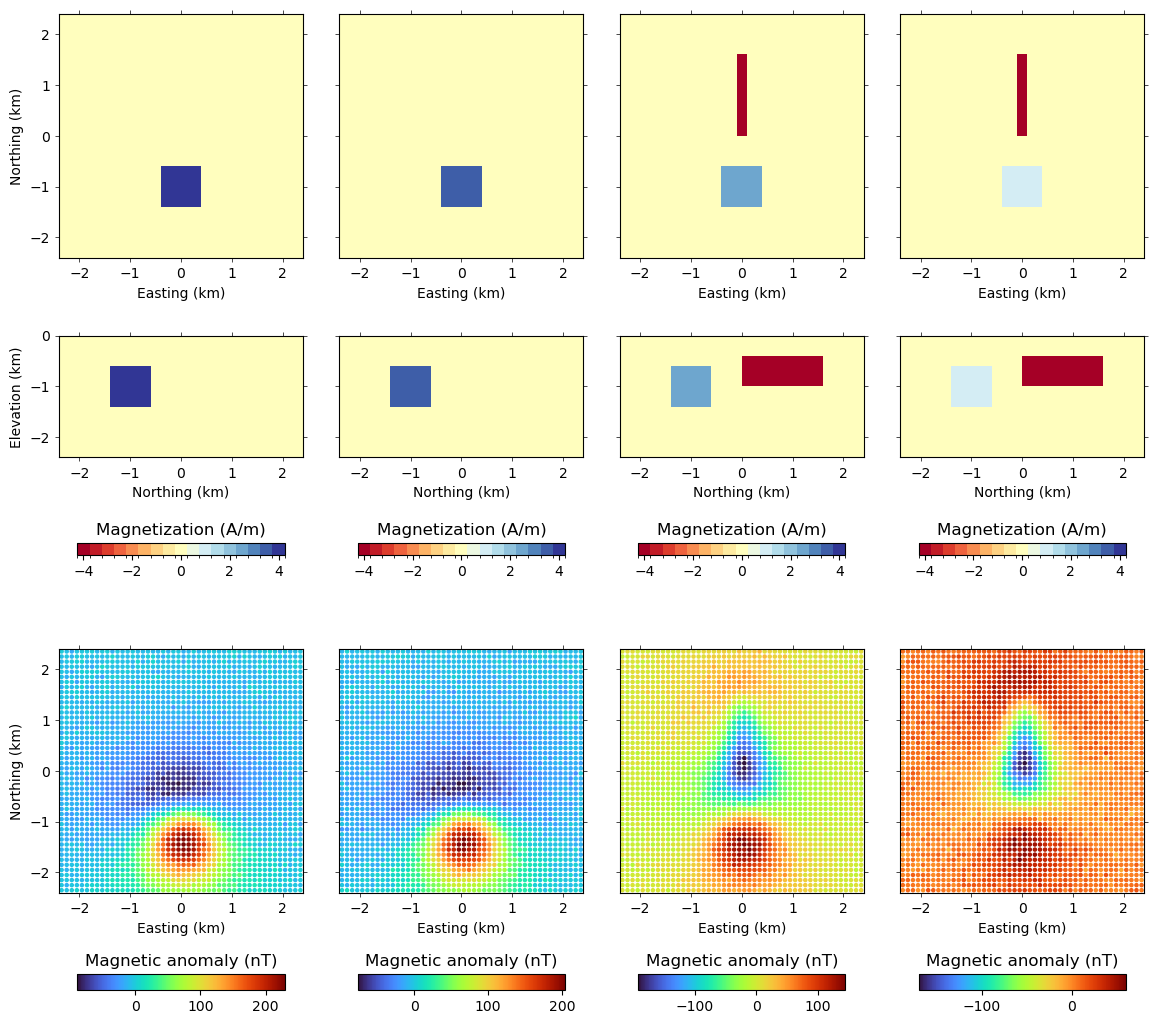

In [8]:
%%time

from matplotlib.gridspec import GridSpec
from matplotlib.colors import BoundaryNorm
import matplotlib as mpl

fig = plt.figure(figsize=(14, 13))

gs = GridSpec(
    5, 4,
    figure=fig,
    width_ratios=[1, 1, 1, 1],
    height_ratios=[4.8, 2.4, 0.8, 4.8, 0.8],
    wspace=0.15,
    hspace=0.5
)

#--- Input model ---#

# Colormap
bounds = np.arange(-4.25, 4.26, 0.5)
cmap = plt.get_cmap("RdYlBu")
norm = BoundaryNorm(bounds, cmap.N)

### T = T1 ###

# Horizontal section
ax = fig.add_subplot(gs[0, 0])

# Cross section
for i in range(len(xgrd)):
    
    # coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # condition
    if (z_min <= -0.6) & (-0.6 <= z_max):
        
        # block size
        width  = x_max - x_min
        height = y_max - y_min

        beta_val = beta1[i]
        color = cmap(norm(beta_val))

        # draw rectangle
        rect = Rectangle((x_min, y_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("Northing (km)")
#ax.set_title("$T = T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(width = 0.5, length = 3)

# N-S section 
ax = fig.add_subplot(gs[1, 0])

# Cross section
for i in range(len(xgrd)):
    
    # coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # condition
    if (x_min <= 0.5*incx) & (0.5*incx <= x_max):
        
        # block size
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta1[i]
        color = cmap(norm(beta_val))

        # draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)
        
ax.set_xticks([-3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("Elevation (km)")
#ax.set_title("$T = T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([])  # required (can be empty)
cax = inset_axes(ax,
                 width="85%",
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.8, 1, 1),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal", ticks=[-4, -2, 0, 2, 4])
#cbar.set_label("Magnetization Intensity (A/m)", rotation=0, labelpad=10, size=12)
cbar.ax.set_title("Magnetization (A/m)", fontsize = 12)


### T = T2 ###

# Horizontal section
ax = fig.add_subplot(gs[0, 1])

# Cross section
for i in range(len(xgrd)):
    
    # coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # condition
    if (z_min <= -0.6) & (-0.6 <= z_max):
        
        # block size
        width  = x_max - x_min
        height = y_max - y_min

        beta_val = beta2[i]
        color = cmap(norm(beta_val))

        # draw rectangle
        rect = Rectangle((x_min, y_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_xlabel("Easting (km)")
#ax.set_ylabel("Northing (km)")
#ax.set_title("$T = T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 0.5, length = 3)

# N-S section 
ax = fig.add_subplot(gs[1, 1])

# Cross section
for i in range(len(xgrd)):
    
    # coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # condition
    if (x_min <= 0.5*incx) & (0.5*incx <= x_max):
        
        # block size
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta2[i]
        color = cmap(norm(beta_val))

        # draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)
        
ax.set_xticks([-3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
ax.set_xlabel("Northing (km)")
#ax.set_ylabel("Elevation (km)")
#ax.set_title("$T = T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([])  # required (can be empty)
cax = inset_axes(ax,
                 width="85%",
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.8, 1, 1),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal", ticks=[-4, -2, 0, 2, 4])
#cbar.set_label("Magnetization Intensity (A/m)", rotation=0, labelpad=10, size=12)
cbar.ax.set_title("Magnetization (A/m)", fontsize = 12)


### T = T3 ###

# Horizontal section
ax = fig.add_subplot(gs[0, 2])

# Cross section
for i in range(len(xgrd)):
    
    # coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # condition
    if (z_min <= -0.6) & (-0.6 <= z_max):
        
        # block size
        width  = x_max - x_min
        height = y_max - y_min

        beta_val = beta3[i]
        color = cmap(norm(beta_val))

        # draw rectangle
        rect = Rectangle((x_min, y_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_xlabel("Easting (km)")
#ax.set_ylabel("Northing (km)")
#ax.set_title("$T = T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 0.5, length = 3)

# N-S section 
ax = fig.add_subplot(gs[1, 2])

# Cross section
for i in range(len(xgrd)):
    
    # coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # condition
    if (x_min <= 0.5*incx) & (0.5*incx <= x_max):
        
        # block size
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta3[i]
        color = cmap(norm(beta_val))

        # draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)
        
ax.set_xticks([-3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
ax.set_xlabel("Northing (km)")
#ax.set_ylabel("Elevation (km)")
#ax.set_title("$T = T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([])  # required (can be empty)
cax = inset_axes(ax,
                 width="85%",
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.8, 1, 1),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal", ticks=[-4, -2, 0, 2, 4])
#cbar.set_label("Magnetization Intensity (A/m)", rotation=0, labelpad=10, size=12)
cbar.ax.set_title("Magnetization (A/m)", fontsize = 12)


### T = T4 ###

# Horizontal section
ax = fig.add_subplot(gs[0, 3])

# Cross section
for i in range(len(xgrd)):
    
    # coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # condition
    if (z_min <= -0.6) & (-0.6 <= z_max):
        
        # block size
        width  = x_max - x_min
        height = y_max - y_min

        beta_val = beta4[i]
        color = cmap(norm(beta_val))

        # draw rectangle
        rect = Rectangle((x_min, y_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_xlabel("Easting (km)")
#ax.set_ylabel("Northing (km)")
#ax.set_title("$T = T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 0.5, length = 3)

# N-S section 
ax = fig.add_subplot(gs[1, 3])

# Cross section
for i in range(len(xgrd)):
    
    # coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # condition
    if (x_min <= 0.5*incx) & (0.5*incx <= x_max):
        
        # block size
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta4[i]
        color = cmap(norm(beta_val))

        # draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)
        
ax.set_xticks([-3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
ax.set_xlabel("Northing (km)")
#ax.set_ylabel("Elevation (km)")
#ax.set_title("$T = T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([])  # required (can be empty)
cax = inset_axes(ax,
                 width="85%",
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.8, 1, 1),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal", ticks=[-4, -2, 0, 2, 4])
#cbar.set_label("Magnetization Intensity (A/m)", rotation=0, labelpad=10, size=12)
cbar.ax.set_title("Magnetization (A/m)", fontsize = 12)



#--- Data ---#

# T = T_1
ax = fig.add_subplot(gs[3, 0])
p = ax.scatter(xobs1, yobs1, c = fobs1, cmap = "turbo", s = 5)
#p.set_clim(-200, 100)
ax.set_aspect("equal")
ax.set_xlabel("Easting (km)")
ax.set_ylabel("Northing (km)")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_xticks([-2, -1, 0, 1, 2])
ax.set_yticks([-2, -1, 0, 1, 2])
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---# 
cmap = cm.get_cmap("turbo")
norm = Normalize(vmin = fobs1.min(), vmax = fobs1.max())
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([])
cax = inset_axes(ax,
                 width="85%", 
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.4, 1, 0.65), 
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal")
cbar.ax.set_title("Magnetic anomaly (nT)", fontsize = 12)

# T = T_2
ax = fig.add_subplot(gs[3, 1])
p = ax.scatter(xobs1, yobs1, c = fobs2, cmap = "turbo", s = 5)
#p.set_clim(-100, 50)
ax.set_aspect("equal")
ax.set_xlabel("Easting (km)")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_xticks([-2, -1, 0, 1, 2])
ax.set_yticks([-2, -1, 0, 1, 2])
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
cmap = cm.get_cmap("turbo")
norm = Normalize(vmin = fobs2.min(), vmax = fobs2.max())
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([]) 
cax = inset_axes(ax,
                 width="85%", 
                 height="10%", 
                 loc='lower center',
                 bbox_to_anchor=(0, -0.4, 1, 0.65),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal")
cbar.ax.set_title("Magnetic anomaly (nT)", fontsize = 12)

# T = T_3
ax = fig.add_subplot(gs[3, 2])
p = ax.scatter(xobs1, yobs1, c = fobs3, cmap = "turbo", s = 5)
#p.set_clim(-30, 50)
ax.set_aspect("equal")
ax.set_xlabel("Easting (km)")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_xticks([-2, -1, 0, 1, 2])
ax.set_yticks([-2, -1, 0, 1, 2])
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
cmap = cm.get_cmap("turbo")
norm = Normalize(vmin = fobs3.min(), vmax = fobs3.max())
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([]) 
cax = inset_axes(ax,
                 width="85%",
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.4, 1, 0.65), 
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal")
cbar.ax.set_title("Magnetic anomaly (nT)", fontsize = 12)

# T = T_4
ax = fig.add_subplot(gs[3, 3])
p = ax.scatter(xobs1, yobs1, c = fobs4, cmap = "turbo", s = 5)
#p.set_clim(-100, 200)
ax.set_aspect("equal")
ax.set_xlabel("Easting (km)")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_xticks([-2, -1, 0, 1, 2])
ax.set_yticks([-2, -1, 0, 1, 2])
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
cmap = cm.get_cmap("turbo")
norm = Normalize(vmin = fobs4.min(), vmax = fobs4.max())
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([]) 
cax = inset_axes(ax,
                 width="85%", 
                 height="10%", 
                 loc='lower center',
                 bbox_to_anchor=(0, -0.4, 1, 0.65),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal")
cbar.ax.set_title("Magnetic anomaly (nT)", fontsize = 12)

plt.savefig("1009_model_C_all_models_and_data.svg", dpi = 600)

<timed exec>:336: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
<timed exec>:366: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
<timed exec>:396: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.


CPU times: total: 36.9 s
Wall time: 37.4 s


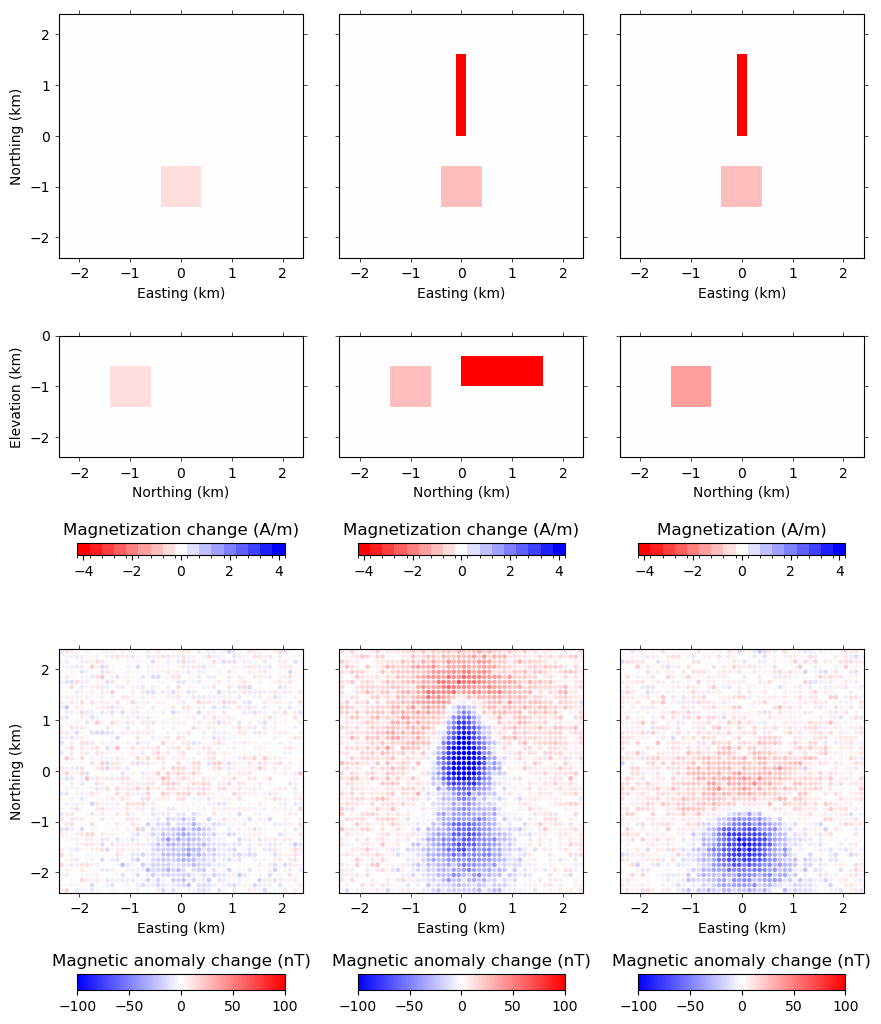

In [9]:
%%time

from matplotlib.gridspec import GridSpec
from matplotlib.colors import BoundaryNorm
import matplotlib as mpl

fig = plt.figure(figsize=(14, 13))

gs = GridSpec(
    5, 4,
    figure=fig,
    width_ratios=[1, 1, 1, 1],
    height_ratios=[4.8, 2.4, 0.8, 4.8, 0.8],
    wspace=0.15,
    hspace=0.5
)

#--- Input model ---#

# Colormap
bounds = np.arange(-4.25, 4.26, 0.5)
cmap = plt.get_cmap("bwr_r")
norm = BoundaryNorm(bounds, cmap.N)

### T2 - T1 ###

# Horizontal section
ax = fig.add_subplot(gs[0, 0])

# Cross section
for i in range(len(xgrd)):
    
    # coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # condition
    if (z_min <= -0.6) & (-0.6 <= z_max):
        
        # block size
        width  = x_max - x_min
        height = y_max - y_min

        beta_val = (beta2 - beta1)[i]
        color = cmap(norm(beta_val))

        # draw rectangle
        rect = Rectangle((x_min, y_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("Northing (km)")
#ax.set_title("$T = T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(width = 0.5, length = 3)

# N-S section 
ax = fig.add_subplot(gs[1, 0])

# Cross section
for i in range(len(xgrd)):
    
    # coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # condition
    if (x_min <= 0.5*incx) & (0.5*incx <= x_max):
        
        # block size
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = (beta2 - beta1)[i]
        color = cmap(norm(beta_val))

        # draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)
        
ax.set_xticks([-3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("Elevation (km)")
#ax.set_title("$T = T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([])  # required (can be empty)
cax = inset_axes(ax,
                 width="85%",
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.8, 1, 1),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal", ticks=[-4, -2, 0, 2, 4])
#cbar.set_label("Magnetization Intensity (A/m)", rotation=0, labelpad=10, size=12)
cbar.ax.set_title("Magnetization change (A/m)", fontsize = 12)


### T3 - T2 ###

# Horizontal section
ax = fig.add_subplot(gs[0, 1])

# Cross section
for i in range(len(xgrd)):
    
    # coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # condition
    if (z_min <= -0.6) & (-0.6 <= z_max):
        
        # block size
        width  = x_max - x_min
        height = y_max - y_min

        beta_val = (beta3 - beta2)[i]
        color = cmap(norm(beta_val))

        # draw rectangle
        rect = Rectangle((x_min, y_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_xlabel("Easting (km)")
#ax.set_ylabel("Northing (km)")
#ax.set_title("$T = T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 0.5, length = 3)

# N-S section 
ax = fig.add_subplot(gs[1, 1])

# Cross section
for i in range(len(xgrd)):
    
    # coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # condition
    if (x_min <= 0.5*incx) & (0.5*incx <= x_max):
        
        # block size
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = (beta3 - beta2)[i]
        color = cmap(norm(beta_val))

        # draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)
        
ax.set_xticks([-3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
ax.set_xlabel("Northing (km)")
#ax.set_ylabel("Elevation (km)")
#ax.set_title("$T = T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([])  # required (can be empty)
cax = inset_axes(ax,
                 width="85%",
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.8, 1, 1),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal", ticks=[-4, -2, 0, 2, 4])
#cbar.set_label("Magnetization Intensity (A/m)", rotation=0, labelpad=10, size=12)
cbar.ax.set_title("Magnetization change (A/m)", fontsize = 12)


### T4 - T3 ###

# Horizontal section
ax = fig.add_subplot(gs[0, 2])

# Cross section
for i in range(len(xgrd)):
    
    # coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # condition
    if (z_min <= -0.6) & (-0.6 <= z_max):
        
        # block size
        width  = x_max - x_min
        height = y_max - y_min

        beta_val = (beta3 - beta2)[i]
        color = cmap(norm(beta_val))

        # draw rectangle
        rect = Rectangle((x_min, y_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_xlabel("Easting (km)")
#ax.set_ylabel("Northing (km)")
#ax.set_title("$T = T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 0.5, length = 3)

# N-S section 
ax = fig.add_subplot(gs[1, 2])

# Cross section
for i in range(len(xgrd)):
    
    # coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # condition
    if (x_min <= 0.5*incx) & (0.5*incx <= x_max):
        
        # block size
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = (beta4 - beta3)[i]
        color = cmap(norm(beta_val))

        # draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)
        
ax.set_xticks([-3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
ax.set_xlabel("Northing (km)")
#ax.set_ylabel("Elevation (km)")
#ax.set_title("$T = T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([])  # required (can be empty)
cax = inset_axes(ax,
                 width="85%",
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.8, 1, 1),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal", ticks=[-4, -2, 0, 2, 4])
#cbar.set_label("Magnetization Intensity (A/m)", rotation=0, labelpad=10, size=12)
cbar.ax.set_title("Magnetization (A/m)", fontsize = 12)


#--- Data ---#

# T_2 - T_1
ax = fig.add_subplot(gs[3, 0])
p = ax.scatter(xobs1, yobs1, c = fobs2 - fobs1, cmap = "bwr", s = 5)
p.set_clim(-100, 100)
ax.set_aspect("equal")
ax.set_xlabel("Easting (km)")
ax.set_ylabel("Northing (km)")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_xticks([-2, -1, 0, 1, 2])
ax.set_yticks([-2, -1, 0, 1, 2])
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---# 
cmap = cm.get_cmap("bwr")
norm = Normalize(vmin = -100, vmax = 100)
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([])
cax = inset_axes(ax,
                 width="85%", 
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.4, 1, 0.65), 
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal")
cbar.ax.set_title("Magnetic anomaly change (nT)", fontsize = 12)

# T_3 - T_2
ax = fig.add_subplot(gs[3, 1])
p = ax.scatter(xobs1, yobs1, c = fobs3 - fobs2, cmap = "bwr", s = 5)
p.set_clim(-100, 100)
ax.set_aspect("equal")
ax.set_xlabel("Easting (km)")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_xticks([-2, -1, 0, 1, 2])
ax.set_yticks([-2, -1, 0, 1, 2])
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
cmap = cm.get_cmap("bwr")
norm = Normalize(vmin = -100, vmax = 100)
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([]) 
cax = inset_axes(ax,
                 width="85%", 
                 height="10%", 
                 loc='lower center',
                 bbox_to_anchor=(0, -0.4, 1, 0.65),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal")
cbar.ax.set_title("Magnetic anomaly change (nT)", fontsize = 12)

# T_4 - T_3
ax = fig.add_subplot(gs[3, 2])
p = ax.scatter(xobs1, yobs1, c = fobs4 - fobs3, cmap = "bwr", s = 5)
p.set_clim(-100, 100)
ax.set_aspect("equal")
ax.set_xlabel("Easting (km)")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_xticks([-2, -1, 0, 1, 2])
ax.set_yticks([-2, -1, 0, 1, 2])
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
cmap = cm.get_cmap("bwr")
norm = Normalize(vmin = -100, vmax = 100)
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([]) 
cax = inset_axes(ax,
                 width="85%",
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.4, 1, 0.65), 
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal")
cbar.ax.set_title("Magnetic anomaly change (nT)", fontsize = 12)

plt.savefig("1009_model_C_all_models_and_data_variations.svg", dpi = 600)

### Estimated models

#### L2-based-4D

In [12]:
# Read
import numpy.core as np_core

# NumPy 2.x の内部モジュール名を NumPy 1.x に対応付ける
sys.modules['numpy._core'] = np_core
sys.modules['numpy._core.multiarray'] = np_core.multiarray
sys.modules['numpy._core.numeric'] = np_core.numeric

with open('0901_Params_model_C_old_4d-2.pickle', 'rb') as f:
    params_old_4d = pickle.load(f)
with open('0901_Betas1_model_C_old_4d-2.pickle', 'rb') as f:
    betas1_old_4d = pickle.load(f)
with open('0901_Betas2_model_C_old_4d-2.pickle', 'rb') as f:
    betas2_old_4d = pickle.load(f)
with open('0901_Betas3_model_C_old_4d-2.pickle', 'rb') as f:
    betas3_old_4d = pickle.load(f)
with open('0901_Betas4_model_C_old_4d-2.pickle', 'rb') as f:
    betas4_old_4d = pickle.load(f)

# optimal parameter  # estimated by L-curve  # For more details, refer to the executable file
num_opt_old_4d = 6
print("Optimal λs = {:.2f}, λt = {:.2f}".format(params_old_4d[num_opt_old_4d][0], params_old_4d[num_opt_old_4d][1]))

# optimal models
beta1_old_4d_temp = betas1_old_4d[num_opt_old_4d]
beta2_old_4d_temp = betas2_old_4d[num_opt_old_4d]
beta3_old_4d_temp = betas3_old_4d[num_opt_old_4d]
beta4_old_4d_temp = betas4_old_4d[num_opt_old_4d]

Optimal λs = 31.62, λt = 31.62


#### SC-TLI

In [26]:
# Read
with open('1004_Params_model_C_new_4d-3.pickle', 'rb') as f:
    params_new_4d = pickle.load(f)
with open('1004_Betas1_model_C_new_4d-3.pickle', 'rb') as f:
    betas1_new_4d = pickle.load(f)
with open('1004_Betas2_model_C_new_4d-3.pickle', 'rb') as f:
    betas2_new_4d = pickle.load(f)
with open('1004_Betas3_model_C_new_4d-3.pickle', 'rb') as f:
    betas3_new_4d = pickle.load(f)
with open('1004_Betas4_model_C_new_4d-3.pickle', 'rb') as f:
    betas4_new_4d = pickle.load(f)

# optimal parameter  # estimated by L-curve  # For more details, refer to the executable file
num_opt_new_4d = 3
print("Optimal λs = {:.2f}, λt = {:.2f}".format(params_new_4d[num_opt_new_4d][0], params_new_4d[num_opt_new_4d][1]))

# optimal models
beta1_new_4d_temp = betas1_new_4d[num_opt_new_4d]
beta2_new_4d_temp = betas2_new_4d[num_opt_new_4d]
beta3_new_4d_temp = betas3_new_4d[num_opt_new_4d]
beta4_new_4d_temp = betas4_new_4d[num_opt_new_4d]

Optimal λs = 17.78, λt = 3.16


### RMSE & SSIM

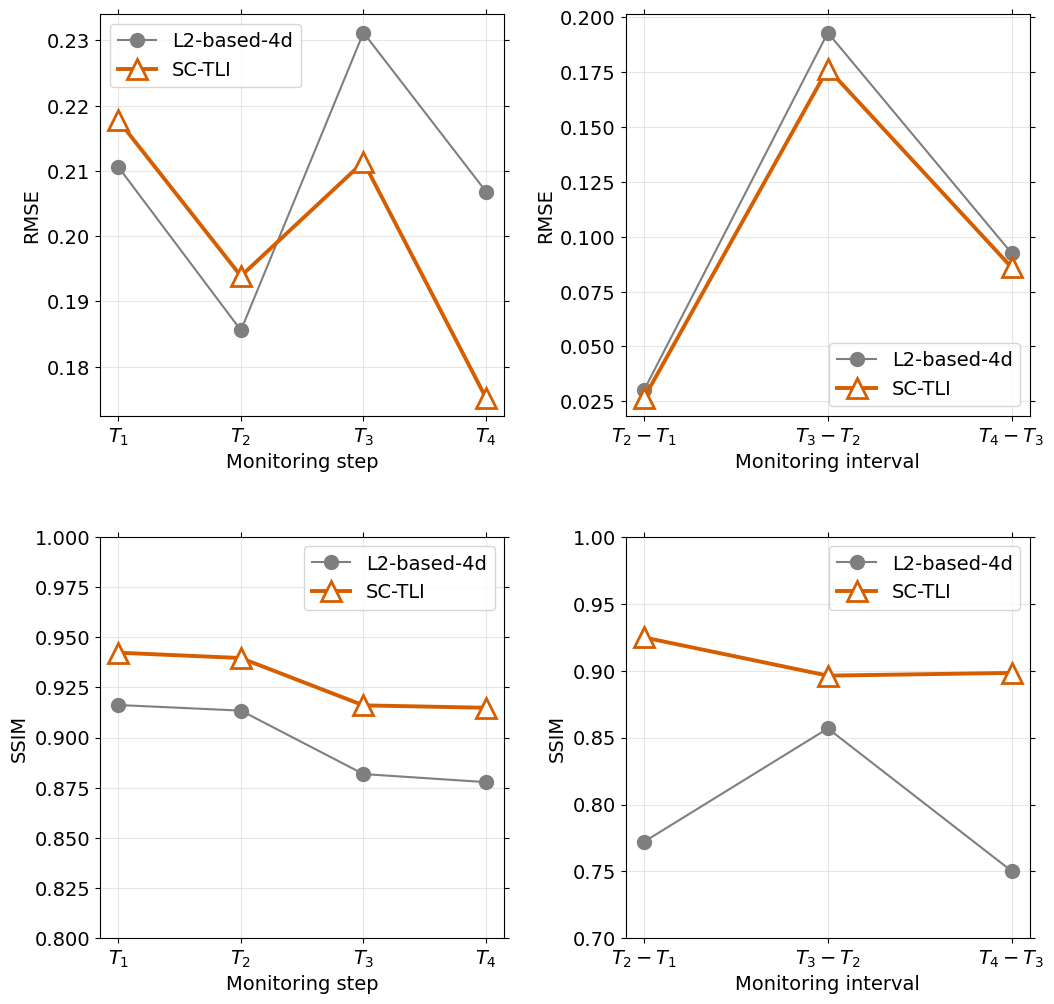

In [21]:
# figure
fig = plt.figure(figsize=(12, 12))
plt.subplots_adjust(wspace=0.3, hspace=0.3)

# --- RMSE for each model --- # 

times = ["$T_1$", "$T_2$", "$T_3$", "$T_4$"]

old_4d = [calc_rmse(beta1, beta1_old_4d_temp),
          calc_rmse(beta2, beta2_old_4d_temp),
          calc_rmse(beta3, beta3_old_4d_temp), 
          calc_rmse(beta4, beta4_old_4d_temp)
         ]

sc_tli = [calc_rmse(beta1, beta1_new_4d_temp),
          calc_rmse(beta2, beta2_new_4d_temp),
          calc_rmse(beta3, beta3_new_4d_temp), 
          calc_rmse(beta4, beta4_new_4d_temp)
         ]

ax = fig.add_subplot(221)

ax.plot(times, old_4d, marker="o", linewidth=1.5, markersize=10, label="L2-based-4d", color="#7F7F7F",)
ax.plot(times, sc_tli, marker="^", linewidth=2.8, markersize=15, color="#D55E00", markerfacecolor="white", markeredgewidth=2.0, label="SC-TLI")

ax.set_xlabel("Monitoring step", fontsize = 14)
ax.set_ylabel("RMSE", fontsize = 14)

#ax.set_ylim(0.84, 1)

ax.grid(True, alpha=0.3)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.legend(fontsize = 14)

plt.tick_params(labelsize=14)


# --- RMSE for tempral change --- #

times = ["$T_2 - T_1$", "$T_3 - T_2$", "$T_4 - T_3$"]

old_4d  = [calc_rmse(beta2 - beta1, beta2_old_4d_temp - beta1_old_4d_temp),
           calc_rmse(beta3 - beta2, beta3_old_4d_temp - beta2_old_4d_temp),
           calc_rmse(beta4 - beta3, beta4_old_4d_temp - beta3_old_4d_temp),
          ]
sc_tli = [calc_rmse(beta2 - beta1, beta2_new_4d_temp - beta1_new_4d_temp),
          calc_rmse(beta3 - beta2, beta3_new_4d_temp - beta2_new_4d_temp),
          calc_rmse(beta4 - beta3, beta4_new_4d_temp - beta3_new_4d_temp),
         ]

ax = fig.add_subplot(222)

ax.plot(times, old_4d, marker="o", linewidth=1.5, markersize=10, label="L2-based-4d", color="#7F7F7F",)
ax.plot(times, sc_tli, marker="^", linewidth=2.8, markersize=15, color="#D55E00", markerfacecolor="white", markeredgewidth=2.0, label="SC-TLI")

ax.set_xlabel("Monitoring interval", fontsize = 14)
ax.set_ylabel("RMSE", fontsize = 14)

# SSIMなので0～1を基本にする
#ax.set_ylim(0.7, 1)

ax.grid(True, alpha=0.3)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.legend(fontsize = 14)

plt.tick_params(labelsize=14)


# --- SSIM for each model --- # 
from skimage.metrics import structural_similarity as ssim

times = ["$T_1$", "$T_2$", "$T_3$", "$T_4$"]

old_4d = [ssim(bb1, beta1_old_4d_temp.reshape(bb1.shape), data_range=beta1.max() - beta1.min(), channel_axis=None), 
          ssim(bb2, beta2_old_4d_temp.reshape(bb2.shape), data_range=beta2.max() - beta2.min(), channel_axis=None), 
          ssim(bb3, beta3_old_4d_temp.reshape(bb3.shape), data_range=beta3.max() - beta3.min(), channel_axis=None), 
          ssim(bb4, beta4_old_4d_temp.reshape(bb4.shape), data_range=beta4.max() - beta4.min(), channel_axis=None)
         ]
sc_tli = [ssim(bb1, beta1_new_4d_temp.reshape(bb1.shape), data_range=beta1.max() - beta1.min(), channel_axis=None), 
          ssim(bb2, beta2_new_4d_temp.reshape(bb2.shape), data_range=beta2.max() - beta2.min(), channel_axis=None), 
          ssim(bb3, beta3_new_4d_temp.reshape(bb3.shape), data_range=beta3.max() - beta3.min(), channel_axis=None), 
          ssim(bb4, beta4_new_4d_temp.reshape(bb4.shape), data_range=beta4.max() - beta4.min(), channel_axis=None)
         ]

ax = fig.add_subplot(223)

ax.plot(times, old_4d, marker="o", linewidth=1.5, markersize=10, label="L2-based-4d", color="#7F7F7F",)
ax.plot(times, sc_tli, marker="^", linewidth=2.8, markersize=15, color="#D55E00", markerfacecolor="white", markeredgewidth=2.0, label="SC-TLI")

ax.set_xlabel("Monitoring step", fontsize = 14)
ax.set_ylabel("SSIM", fontsize = 14)

# SSIMなので0～1を基本にする
ax.set_ylim(0.8, 1.0)

ax.grid(True, alpha=0.3)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.legend(fontsize = 14)

plt.tick_params(labelsize=14)


# --- SSIM for temporal change --- #

times = ["$T_2 - T_1$", "$T_3 - T_2$", "$T_4 - T_3$"]

old_4d = [ssim(bb2 - bb1, (beta2_old_4d_temp - beta1_old_4d_temp).reshape(bb1.shape), 
               data_range=(beta2 - beta1).max() - (beta2 - beta1).min(), channel_axis=None),
          ssim(bb3 - bb2, (beta3_old_4d_temp - beta2_old_4d_temp).reshape(bb1.shape), 
               data_range=(beta3 - beta2).max() - (beta3 - beta2).min(), channel_axis=None),
          ssim(bb4 - bb3, (beta4_old_4d_temp - beta3_old_4d_temp).reshape(bb1.shape), 
               data_range=(beta4 - beta3).max() - (beta4 - beta3).min(), channel_axis=None),
         ]
sc_tli = [ssim(bb2 - bb1, (beta2_new_4d_temp - beta1_new_4d_temp).reshape(bb1.shape), 
               data_range=(beta2 - beta1).max() - (beta2 - beta1).min(), channel_axis=None),
          ssim(bb3 - bb2, (beta3_new_4d_temp - beta2_new_4d_temp).reshape(bb1.shape), 
               data_range=(beta3 - beta2).max() - (beta3 - beta2).min(), channel_axis=None),
          ssim(bb4 - bb3, (beta4_new_4d_temp - beta3_new_4d_temp).reshape(bb1.shape), 
               data_range=(beta4 - beta3).max() - (beta4 - beta3).min(), channel_axis=None),
         ]

ax = fig.add_subplot(224)

ax.plot(times, old_4d, marker="o", linewidth=1.5, markersize=10, label="L2-based-4d", color="#7F7F7F",)
ax.plot(times, sc_tli, marker="^", linewidth=2.8, markersize=15, color="#D55E00", markerfacecolor="white", markeredgewidth=2.0, label="SC-TLI")

ax.set_xlabel("Monitoring interval", fontsize = 14)
ax.set_ylabel("SSIM", fontsize = 14)

# SSIMなので0～1を基本にする
ax.set_ylim(0.7, 1.0)

ax.grid(True, alpha=0.3)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.legend(fontsize = 14)

plt.tick_params(labelsize=14)

plt.savefig("1009_model_C_RMSE_and_SSIM.svg", dpi = 600)

### Figure

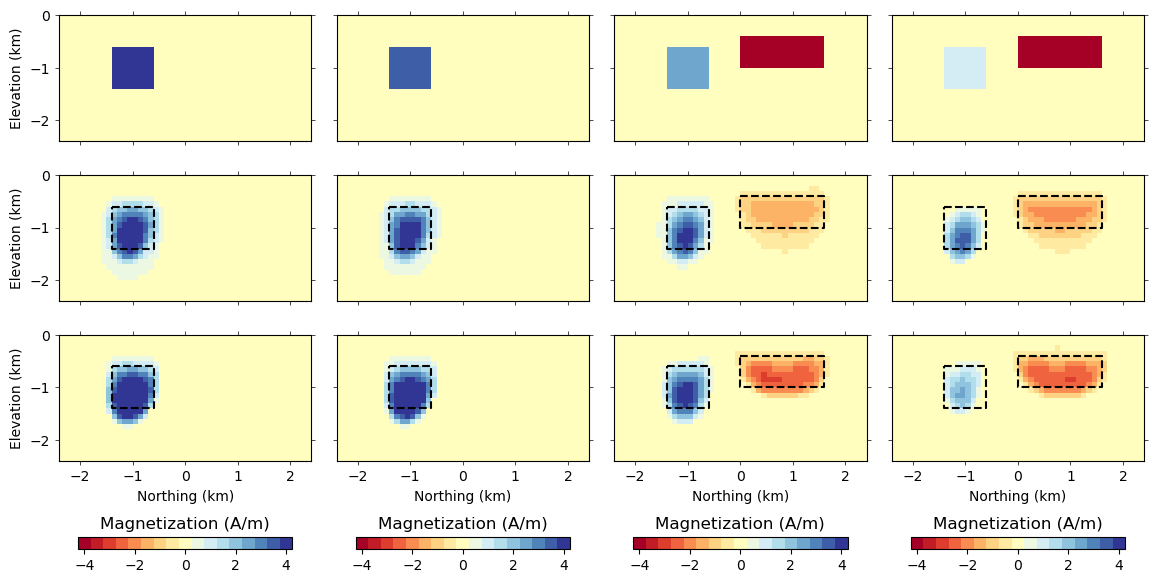

In [27]:
# Colormap
from matplotlib.colors import BoundaryNorm
bounds = np.arange(-4.25, 4.26, 0.5)
cmap = plt.get_cmap("RdYlBu")
norm = BoundaryNorm(bounds, cmap.N)

# Figure setup
fig = plt.figure(figsize = (14, 10))
plt.subplots_adjust(wspace=0.1, hspace=-0.45)

#--- Input models ---#

# T = T1
ax = fig.add_subplot(445)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Slice condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta1[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

#ax.plot([1.1, 0.3, 0.3, 1.1, 1.1], [-0.4, -0.4, -1.2, -1.2, -0.4], "--", color = "k")
#ax.plot([-0.3, -1.1, -1.1, -0.3, -0.3], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
#ax.set_xlabel("Easting (km)")
ax.set_ylabel("Elevation (km)")
#ax.set_title("$T = T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelbottom=False)
ax.tick_params(width = 0.5, length = 3)

#ax.text(-0.35, 0.5, "Input models", fontsize=14,
#        rotation=90, va='center', ha='center',
#        transform=ax.transAxes)

# T = T2
ax = fig.add_subplot(446)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Slice condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta2[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

#ax.plot([1.1, 0.3, 0.3, 1.1, 1.1], [-0.4, -0.4, -1.2, -1.2, -0.4], "--", color = "k")
#ax.plot([-0.3, -1.1, -1.1, -0.3, -0.3], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
#ax.set_xlabel("Easting (km)")
#ax.set_ylabel("Altitude (km)")
#ax.set_title("$T = T_2$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, labelbottom=False)
ax.tick_params(width = 0.5, length = 3)

# T = T3
ax = fig.add_subplot(447)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Slice condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta3[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

#ax.plot([1.1, 0.3, 0.3, 1.1, 1.1], [-0.4, -0.4, -1.2, -1.2, -0.4], "--", color = "k")
#ax.plot([-0.3, -1.1, -1.1, -0.3, -0.3], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
#ax.set_xlabel("Easting (km)")
#ax.set_ylabel("Altitude (km)")
#ax.set_title("$T = T_3$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, labelbottom=False)
ax.tick_params(width = 0.5, length = 3)

# T = T4
ax = fig.add_subplot(448)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Slice condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta4[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

#ax.plot([1.1, 0.3, 0.3, 1.1, 1.1], [-0.4, -0.4, -1.2, -1.2, -0.4], "--", color = "k")
#ax.plot([-0.3, -1.1, -1.1, -0.3, -0.3], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")

ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
#ax.set_xlabel("Easting (km)")
#ax.set_ylabel("Altitude (km)")
#ax.set_title("$T = T_4$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, labelbottom=False)
ax.tick_params(width = 0.5, length = 3)


#--- L2-based-4d ---#

# T = T1
ax = fig.add_subplot(449)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Slice condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta1_old_4d_temp[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

#ax.plot([0.0, 1.6, 1.6, 0.0, 0.0], [-0.4, -0.4, -1.0, -1.0, -0.4], "--", color = "k")
ax.plot([-1.4, -0.6, -0.6, -1.4, -1.4], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")

ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
#ax.set_xlabel("Easting (km)")
ax.set_ylabel("Elevation (km)")
#ax.set_title("$T = T_1$")
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelbottom=False)
ax.tick_params(width = 0.5, length = 3)

#ax.text(-0.35, 0.5, "Parallel inv.", fontsize=14,
#        rotation=90, va='center', ha='center',
#        transform=ax.transAxes)

# T = T2
ax = fig.add_subplot(4,4,10)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Slice condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta2_old_4d_temp[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

#ax.plot([0.0, 1.6, 1.6, 0.0, 0.0], [-0.4, -0.4, -1.0, -1.0, -0.4], "--", color = "k")
ax.plot([-1.4, -0.6, -0.6, -1.4, -1.4], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
#ax.set_xlabel("Easting (km)")
#ax.set_ylabel("Altitude (km)")
#ax.set_title("$T = T_2$")
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, labelbottom=False)
ax.tick_params(width = 0.5, length = 3)

# T = T3
ax = fig.add_subplot(4,4,11)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Slice condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta3_old_4d_temp[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

ax.plot([0.0, 1.6, 1.6, 0.0, 0.0], [-0.4, -0.4, -1.0, -1.0, -0.4], "--", color = "k")
ax.plot([-1.4, -0.6, -0.6, -1.4, -1.4], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
#ax.set_xlabel("Easting (km)")
#ax.set_ylabel("Altitude (km)")
#ax.set_title("$T = T_3$")
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, labelbottom=False)
ax.tick_params(width = 0.5, length = 3)

# T = T4
ax = fig.add_subplot(4,4,12)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Slice condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta4_old_4d_temp[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

ax.plot([0.0, 1.6, 1.6, 0.0, 0.0], [-0.4, -0.4, -1.0, -1.0, -0.4], "--", color = "k")
ax.plot([-1.4, -0.6, -0.6, -1.4, -1.4], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
#ax.set_xlabel("Easting (km)")
#ax.set_ylabel("Altitude (km)")
#ax.set_title("$T = T_4$")
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, labelbottom=False)
ax.tick_params(width = 0.5, length = 3)



#--- 4D inversion ---#

# T = T1
ax = fig.add_subplot(4,4,13)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Slice condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta1_new_4d_temp[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

ax.plot([-1.4, -0.6, -0.6, -1.4, -1.4], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")

ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("Elevation (km)")
#ax.set_title("$T = T_1$")
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(width = 0.5, length = 3)

#ax.text(-0.35, 0.5, "4D inv.", fontsize=14,
#        rotation=90, va='center', ha='center',
#        transform=ax.transAxes)

#--- colorbar ---#
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([]) 
cax = inset_axes(ax,
                 width="85%", 
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.7, 1, 1), 
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal", ticks=[-4, -2, 0, 2, 4])
#cbar.set_label("Magnetization Intensity (A/m)", rotation=0, labelpad=10, size=12)
cbar.ax.set_title("Magnetization (A/m)", fontsize = 12)
cbar.ax.minorticks_off()

# T = T2
ax = fig.add_subplot(4,4,14)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Slice condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta2_new_4d_temp[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

ax.plot([-1.4, -0.6, -0.6, -1.4, -1.4], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")

ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
ax.set_xlabel("Northing (km)")
#ax.set_ylabel("Altitude (km)")
#ax.set_title("$T = T_2$")
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False)
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
cax = inset_axes(ax,
                 width="85%", 
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.7, 1, 1),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal", ticks=[-4, -2, 0, 2, 4])
#cbar.set_label("Magnetization Intensity (A/m)", rotation=0, labelpad=10, size=12)
cbar.ax.set_title("Magnetization (A/m)", fontsize = 12)
cbar.ax.minorticks_off()

# T = T3
ax = fig.add_subplot(4,4,15)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Slice condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta3_new_4d_temp[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

ax.plot([0.0, 1.6, 1.6, 0.0, 0.0], [-0.4, -0.4, -1.0, -1.0, -0.4], "--", color = "k")
ax.plot([-1.4, -0.6, -0.6, -1.4, -1.4], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")

ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
ax.set_xlabel("Northing (km)")
#ax.set_ylabel("Altitude (km)")
#ax.set_title("$T = T_3$")
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False)
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
cax = inset_axes(ax,
                 width="85%", 
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.7, 1, 1),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal", ticks=[-4, -2, 0, 2, 4])
#cbar.set_label("Magnetization Intensity (A/m)", rotation=0, labelpad=10, size=12)
cbar.ax.set_title("Magnetization (A/m)", fontsize = 12)
cbar.ax.minorticks_off()

# T = T4
ax = fig.add_subplot(4,4,16)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Slice condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = beta4_new_4d_temp[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

ax.plot([0.0, 1.6, 1.6, 0.0, 0.0], [-0.4, -0.4, -1.0, -1.0, -0.4], "--", color = "k")
ax.plot([-1.4, -0.6, -0.6, -1.4, -1.4], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")

ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
ax.set_xlabel("Northing (km)")
#ax.set_ylabel("Altitude (km)")
#ax.set_title("$T = T_4$")
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False)
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
cax = inset_axes(ax,
                 width="85%",
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.7, 1, 1),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal", ticks=[-4, -2, 0, 2, 4])
#cbar.set_label("Magnetization Intensity (A/m)", rotation=0, labelpad=10, size=12)
cbar.ax.set_title("Magnetization (A/m)", fontsize = 12)
cbar.ax.minorticks_off()

plt.savefig("1009_model_C_all_models.svg", dpi = 600, transparent = True)

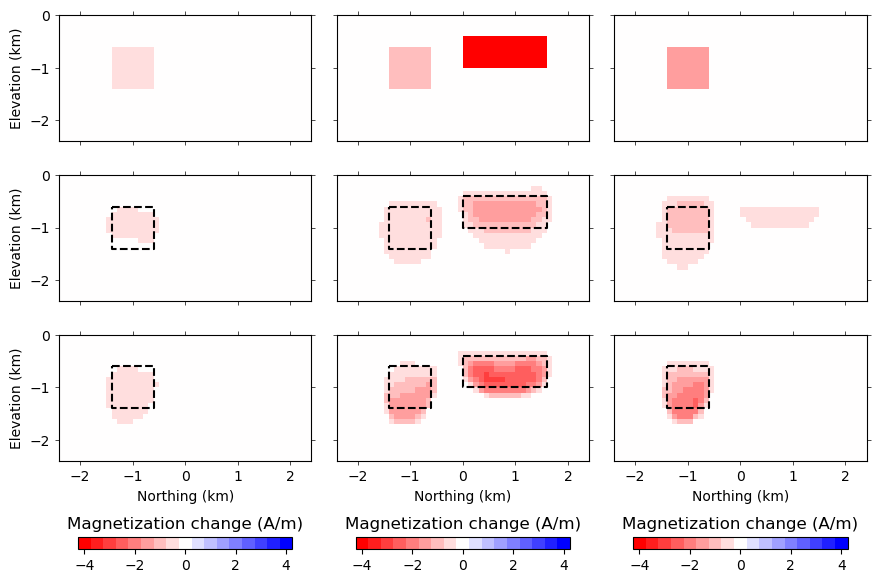

In [28]:
# Colormap
from matplotlib.colors import BoundaryNorm
bounds = np.arange(-4.25, 4.26, 0.5)
cmap = plt.get_cmap("bwr_r")
norm = BoundaryNorm(bounds, cmap.N)

# Figure setup
fig = plt.figure(figsize = (14, 10))
plt.subplots_adjust(wspace=0.1, hspace=-0.45)

#--- Input models ---#

# T2 - T1
ax = fig.add_subplot(445)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = (beta2 - beta1)[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

#ax.plot([1.1, 0.3, 0.3, 1.1, 1.1], [-0.4, -0.4, -1.2, -1.2, -0.4], "--", color = "k")

ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
#ax.set_xlabel("Easting (km)")
ax.set_ylabel("Elevation (km)")
#ax.set_title("$T_2 - T_1$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelbottom=False)
ax.tick_params(width = 0.5, length = 3)

#ax.text(-0.35, 0.5, "Input models", fontsize=14,
#        rotation=90, va='center', ha='center',
#        transform=ax.transAxes)

# T3 - T2
ax = fig.add_subplot(446)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = (beta3 - beta2)[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

#ax.plot([1.1, 0.3, 0.3, 1.1, 1.1], [-0.4, -0.4, -1.2, -1.2, -0.4], "--", color = "k")
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
#ax.set_xlabel("Easting (km)")
#ax.set_ylabel("Altitude (km)")
#ax.set_title("$T_3 - T_2$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, labelbottom=False)
ax.tick_params(width = 0.5, length = 3)

# T4 - T3
ax = fig.add_subplot(447)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (x_min <= 0.5*incx) & (0.5*incx <= x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = (beta4 - beta3)[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

#ax.plot([1.1, 0.3, 0.3, 1.1, 1.1], [-0.4, -0.4, -1.2, -1.2, -0.4], "--", color = "k")
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
#ax.set_xlabel("Easting (km)")
#ax.set_ylabel("Altitude (km)")
#ax.set_title("$T_4 - T_3$", fontsize = 14)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, labelbottom=False)
ax.tick_params(width = 0.5, length = 3)


#--- L2-based-4d ---#

# T2 - T1
ax = fig.add_subplot(449)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = (beta2_old_4d_temp - beta1_old_4d_temp)[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

#ax.plot([0.0, 1.6, 1.6, 0.0, 0.0], [-0.4, -0.4, -1.0, -1.0, -0.4], "--", color = "k")
ax.plot([-1.4, -0.6, -0.6, -1.4, -1.4], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
#ax.set_xlabel("Easting (km)")
ax.set_ylabel("Elevation (km)")
#ax.set_title("$T = T_1$")
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelbottom=False)
ax.tick_params(width = 0.5, length = 3)

#ax.text(-0.35, 0.5, "Parallel inv.", fontsize=14,
#rotation=90, va='center', ha='center',
#        transform=ax.transAxes)

# T3 - T2
ax = fig.add_subplot(4,4,10)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = (beta3_old_4d_temp - beta2_old_4d_temp)[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

ax.plot([0.0, 1.6, 1.6, 0.0, 0.0], [-0.4, -0.4, -1.0, -1.0, -0.4], "--", color = "k")
ax.plot([-1.4, -0.6, -0.6, -1.4, -1.4], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
#ax.set_xlabel("Easting (km)")
#ax.set_ylabel("Altitude (km)")
#ax.set_title("$T = T_2$")
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, labelbottom=False)
ax.tick_params(width = 0.5, length = 3)

# T4 - T3
ax = fig.add_subplot(4,4,11)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = (beta4_old_4d_temp - beta3_old_4d_temp)[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

#ax.plot([0.0, 1.6, 1.6, 0.0, 0.0], [-0.4, -0.4, -1.0, -1.0, -0.4], "--", color = "k")
ax.plot([-1.4, -0.6, -0.6, -1.4, -1.4], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
#ax.set_xlabel("Easting (km)")
#ax.set_ylabel("Altitude (km)")
#ax.set_title("$T = T_3$")
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, labelbottom=False)
ax.tick_params(width = 0.5, length = 3)


#--- 4D inversion ---#

# T2 - T1
ax = fig.add_subplot(4,4,13)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = (beta2_new_4d_temp - beta1_new_4d_temp)[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

#ax.plot([0.0, 1.6, 1.6, 0.0, 0.0], [-0.4, -0.4, -1.0, -1.0, -0.4], "--", color = "k")
ax.plot([-1.4, -0.6, -0.6, -1.4, -1.4], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("Elevation (km)")
#ax.set_title("$T = T_1$")
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(width = 0.5, length = 3)

#ax.text(-0.35, 0.5, "4D inv.", fontsize=14,
#        rotation=90, va='center', ha='center',
#        transform=ax.transAxes)

#--- colorbar ---#
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([])
cax = inset_axes(ax,
                 width="85%",
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.7, 1, 1),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal", cmap = "bwr_r", ticks=[-4, -2, 0, 2, 4])
#cbar.set_label("Magnetization Intensity (A/m)", rotation=0, labelpad=10, size=12)
cbar.ax.set_title("Magnetization change (A/m)", fontsize = 12)
cbar.ax.minorticks_off()

# T3 - T2
ax = fig.add_subplot(4,4,14)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min
        
        beta_val = (beta3_new_4d_temp - beta2_new_4d_temp)[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

ax.plot([0.0, 1.6, 1.6, 0.0, 0.0], [-0.4, -0.4, -1.0, -1.0, -0.4], "--", color = "k")
ax.plot([-1.4, -0.6, -0.6, -1.4, -1.4], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
ax.set_xlabel("Northing (km)")
#ax.set_ylabel("Altitude (km)")
#ax.set_title("$T = T_2$")
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False)
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
cax = inset_axes(ax,
                 width="85%",
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.7, 1, 1),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal", cmap = "bwr_r", ticks=[-4, -2, 0, 2, 4])
#cbar.set_label("Magnetization Intensity (A/m)", rotation=0, labelpad=10, size=12)
cbar.ax.set_title("Magnetization change (A/m)", fontsize = 12)
cbar.ax.minorticks_off()

# T4 - T3
ax = fig.add_subplot(4,4,15)

# Cross-section
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (x_min <= -0.5*incx) & (-0.5*incx < x_max):
        
        # Cell dimensions
        width  = y_max - y_min
        height = z_max - z_min

        beta_val = (beta4_new_4d_temp - beta3_new_4d_temp)[i]
        color = cmap(norm(beta_val))

        # Draw rectangle
        rect = Rectangle((y_min, z_min), width, height,
                         facecolor=color, edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

#ax.plot([0.0, 1.6, 1.6, 0.0, 0.0], [-0.4, -0.4, -1.0, -1.0, -0.4], "--", color = "k")
ax.plot([-1.4, -0.6, -0.6, -1.4, -1.4], [-0.6, -0.6, -1.4, -1.4, -0.6], "--", color = "k")
        
ax.set_xticks([-2.0, -1.0, 0.0, 1.0, 2.0])
ax.set_yticks([-2.0, -1.0, 0.0])
ax.set_aspect("equal")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.0)
ax.set_xlabel("Northing (km)")
#ax.set_ylabel("Altitude (km)")
#ax.set_title("$T = T_3$")
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False)
ax.tick_params(width = 0.5, length = 3)

#--- colorbar ---#
cax = inset_axes(ax,
                 width="85%",  # 横幅（親軸に対する割合）
                 height="10%",  # 高さ（親軸に対する割合）
                 loc='lower center',
                 bbox_to_anchor=(0, -0.7, 1, 1), # 左端、下端
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal", cmap = "bwr_r", ticks=[-4, -2, 0, 2, 4])
#cbar.set_label("Magnetization Intensity (A/m)", rotation=0, labelpad=10, size=12)
cbar.ax.set_title("Magnetization change (A/m)", fontsize = 12)
cbar.ax.minorticks_off()

plt.savefig("1009_model_C_all_temporal_changes.svg", dpi = 600, transparent = True)